# 11 · Gridded data at scale

*Why the shape of the chunks decides what every read costs.*

Everything so far has been tables of stations. Most weather data isn't. Model output, reanalysis and satellite products are **grids**: one value per cell, per time, sometimes per height and per ensemble member. ERA5 alone is petabytes. Nobody loads a grid like that into memory. You open it lazily, slice what you need and only the pieces holding your slice move.

How fast that is depends almost entirely on how the array was cut up when it was written. This notebook shows that with a real, mid-sized array: every hour of HRRR's 2 m temperature over California for 2021–2024 which notebook 03 kept as a side product. One variable is 35,064 hours × 458 × 420 cells (about 27 GB uncompressed). That's too big to treat casually on a laptop and small enough to experiment with.

Three ideas carry it:

- **Zarr** stores an n-dimensional array as a grid of compressed **chunks** (one object each) plus a little JSON. It's the format behind WeatherBench 2, ARCO-ERA5 and ECMWF's Anemoi training data.
- **Chunk shape must match the reader.** A training job reads whole maps. A climate study reads long series at a point. One layout can't be fast for both.
- **Rechunking** converts one layout into another. Done naively it needs the whole array in memory. **dask** and **xarray-beam** do it in steps under a memory limit (the second on any Beam runner up to a cluster).

**Read first:** Zarr's [Quickstart](https://zarr.readthedocs.io/en/stable/quickstart.html) and [user guide on arrays, chunks, compression and sharding](https://zarr.readthedocs.io/en/stable/user-guide/arrays.html); xarray's [Reading and writing Zarr](https://docs.xarray.dev/en/stable/user-guide/io.html#zarr); the [xarray-beam README](https://github.com/google/xarray-beam) and ["Why xarray-beam"](https://xarray-beam.readthedocs.io/en/latest/why-xarray-beam.html). About 45 minutes.

In [1]:
# Setup: identical in every notebook. Data lives in ../data, which git ignores.
import os
DATA_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", "data"))
os.makedirs(DATA_DIR, exist_ok=True)
print("Data directory:", DATA_DIR)

Data directory: /Users/ashu/Workspace/weather-data-lab/data


In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from pathlib import Path
from wxlab import gridded as gd

plt.rcParams["figure.dpi"] = 80
GRID = Path(DATA_DIR) / "reference" / "hrrr_grid_ca"
ZARR = Path(DATA_DIR) / "work" / "zarr"
TRAIN, ANALYSIS, ANALYSIS_BEAM = ZARR / "t2m_training.zarr", ZARR / "t2m_analysis.zarr", ZARR / "t2m_analysis_beam.zarr"
ZARR.mkdir(parents=True, exist_ok=True)

## Step 1 · One labelled cube

The day files are plain NumPy arrays. xarray gives them names and coordinates: a `time` axis, `y` and `x` grid indices and 2D `latitude` and `longitude` because HRRR's grid is a Lambert conformal projection and not a latitude–longitude grid. CF attributes say what the numbers are.

`gd.template` builds that dataset lazily: full shape, coordinates, attributes and no data yet.

In [3]:
tpl = gd.template(GRID)
print(tpl)
print(f"{tpl.air_temperature.nbytes / 1e9:.1f} GB uncompressed")

<xarray.Dataset> Size: 27GB
Dimensions:          (time: 35064, y: 458, x: 420)
Coordinates:
  * time             (time) datetime64[ns] 281kB 2021-01-01 ... 2024-12-31T23...
    latitude         (y, x) float64 2MB 29.84 29.85 29.85 ... 44.43 44.43 44.44
    longitude        (y, x) float64 2MB -124.2 -124.2 -124.2 ... -114.1 -114.0
Dimensions without coordinates: y, x
Data variables:
    air_temperature  (time, y, x) float32 27GB dask.array<chunksize=(744, 458, 420), meta=np.ndarray>
Attributes:
    source:   NOAA HRRR via notebook 03
    grid:     HRRR 3 km Lambert conformal, California crop
27.0 GB uncompressed


## Step 2 · Write the training layout

Training reads whole maps so the first layout uses one chunk per day: 24 hours × the whole state (about 18 MB uncompressed per chunk). Writing happens in units of one month. The template is written first (metadata only) then each month fills its own region of the time axis. A log of finished months makes the job resumable (the same idea as the manifest in notebook 07).

In [4]:
gd.write_training_layout(GRID, TRAIN, chunks=(24, None, None))
train = xr.open_zarr(TRAIN)
print(train.air_temperature.encoding["chunks"], gd.store_stats(TRAIN))

(24, 458, 420) {'objects': 1471, 'gb': 7.438654741}


The store holds 1,461 chunk objects plus a little metadata (about 7.4 GB on disk for 27 GB of values). That's 3.6× smaller thanks to Zarr's default zstd compression. Temperature fields are smooth so neighbouring values compress well. Opening the store read only the JSON metadata. No chunk was touched.

## Step 3 · Rechunk to the analysis layout

The analysis layout cuts the cube into long thin columns: every hour × a 16 × 16 tile (about 36 MB per chunk). Turning day-shaped chunks into column-shaped ones means every output chunk needs a little piece of every one of the 1,461 input chunks. That's the array version of a shuffle.

Doing it in one go is where people get stuck. dask's default rechunk plans the whole thing in memory and is known to run out of it on arrays this size ([Pangeo discussion](https://discourse.pangeo.io/t/rechunking-large-data-at-constant-memory-in-dask-experimental/3266)). The **rechunker** library's answer is to pass through an **intermediate layout** written to disk whose chunks sit between the two ([rechunker algorithm](https://rechunker.readthedocs.io/en/latest/algorithm.html)). Here that's a month of hours by a 64 × 64 tile. Each step then only regroups a few chunks at a time and memory stays bounded. `gd.rechunk_via_intermediate` does those two steps with dask.

Measured under a memory cap the two steps took about 70 seconds and never used more than about 2 GB for a 27 GB array.

In [5]:
import time
from dask.diagnostics import ProgressBar

INTER = ZARR / "t2m_intermediate.zarr"
t0 = time.time()
with ProgressBar(minimum=60):                        # first run: about 70 s, peak memory about 2 GB
    gd.rechunk_via_intermediate(TRAIN, INTER, ANALYSIS,
                                inter_chunks={"time": 24 * 30, "y": 64, "x": 64},
                                target_chunks={"time": -1, "y": 16, "x": 16})
analysis = xr.open_zarr(ANALYSIS)
print(analysis.air_temperature.encoding["chunks"], gd.store_stats(ANALYSIS))

(35064, 16, 16) {'objects': 2351, 'gb': 9.650422433}


## Step 4 · Measure what each read costs

Two typical questions asked of both layouts:

- **one map**: the whole state at one hour, what a training step reads;
- **one place, four years**: every hour at one cell, what a climate study reads.

In [6]:
import json
iy, ix = 230, 210                                    # a cell near the middle of the crop
costs = ZARR / "read_costs.json"
if not costs.exists():                               # about half a minute; result cached
    rows = []
    for name, ds in [("training", train), ("analysis", analysis)]:
        v = ds.air_temperature
        rows.append({"layout": name,
                     "map_chunks": gd.chunks_touched(v, time=1000), "map_s": gd.timed(lambda: v.isel(time=1000).values),
                     "place_chunks": gd.chunks_touched(v, y=iy, x=ix), "place_s": gd.timed(lambda: v.isel(y=iy, x=ix).values, repeat=1)})
    json.dump(rows, open(costs, "w"))
pd.DataFrame(json.load(open(costs))).set_index("layout").rename(columns={
    "map_chunks": "one map: chunks", "map_s": "one map: s", "place_chunks": "one place: chunks", "place_s": "one place: s"}).round(3)

,one map: chunks,one map: s,one place: chunks,one place: s
layout,,,,
training,1,0.017,1461,6.965
analysis,783,7.733,1,0.038


One map from the training layout is a single chunk and takes about 0.02 s. From the analysis layout it's 783 chunks and nearly 8 s (about 450 times slower). Four years at one place is the mirror image: 1,461 chunks and 7 s from the training layout, one chunk and 0.04 s from the analysis layout. Same data, same disk, same laptop. Only the chunk shape changed.

The general rule: a read costs roughly the number of chunks it touches times the cost of one chunk. Chunks that are too small make every read a flood of requests and chunks that are too big make small reads drag in bytes they don't need. On cloud object storage the usual target is about 10–100 MB per chunk. When two kinds of readers matter big producers keep two copies (as ECMWF does with ARCO ERA5).

## Step 5 · The same rechunk with xarray-beam

xarray-beam expresses a rechunk as a Beam pipeline over `(key, chunk)` pairs. `DatasetToChunks` reads the source in its own chunks, `Rechunk` splits and regroups them so no single intermediate chunk is bigger than `max_mem` and `ChunksToZarr` writes the result ([xarray-beam API](https://xarray-beam.readthedocs.io/en/stable/api.html)). The same pipeline runs on Dataflow across hundreds of machines which is how WeatherBench 2 processes ERA5.

On a laptop it's a different story and this notebook learned it the hard way. Recent versions of Beam's local DirectRunner hand pipelines to a runner called Prism ([Beam source](https://beam.apache.org/releases/pydoc/2.72.0/_modules/apache_beam/runners/direct/direct_runner.html)). One week of the cube (0.13 GB of data) peaked at 3.3 GB of memory. A first attempt on a whole year ran the laptop out of memory and crashed it. `max_mem` caps each intermediate chunk and not the memory of the whole pipeline. So here it runs on one week and I check that it gives exactly the same columns as dask.

In [7]:
import apache_beam as beam
import xarray_beam as xbeam

BEAM_WEEK = ZARR / "t2m_analysis_beam_week.zarr"
week = xr.open_zarr(TRAIN, chunks=None).sel(time=slice("2023-01-01", "2023-01-07T23"))
src_chunks, dst_chunks = {"time": 24, "y": -1, "x": -1}, {"time": -1, "y": 16, "x": 16}
if not BEAM_WEEK.exists():                           # about 10 s and 3.3 GB peak memory
    with beam.Pipeline() as p:
        (p | xbeam.DatasetToChunks(week, src_chunks)
           | xbeam.Rechunk(week.sizes, src_chunks, dst_chunks, itemsize=4, max_mem=2**26)
           | xbeam.ChunksToZarr(str(BEAM_WEEK), xbeam.make_template(week), dst_chunks))
a = xr.open_zarr(BEAM_WEEK).air_temperature.isel(y=iy, x=ix).values
b = analysis.air_temperature.sel(time=week.time).isel(y=iy, x=ix).values
print(f"{week.sizes['time']} hours; same as the dask result: {np.array_equal(a, b, equal_nan=True)}")

168 hours; same as the dask result: True


## Step 6 · A computation over the whole cube

Last something useful: the mean temperature for each hour of the day at every cell over four years. That's a 24 × 458 × 420 result from 27 GB of input, computed lazily so only a few chunks are in memory at a time. It runs on the training layout because it needs whole maps in time order.

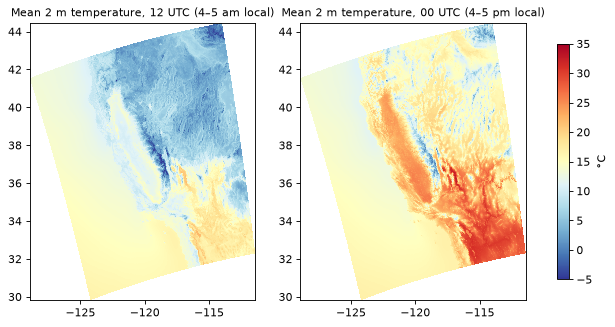

In [8]:
DIURNAL = ZARR / "t2m_diurnal.nc"
if not DIURNAL.exists():                             # about 15 s and 1.6 GB peak memory
    train.air_temperature.groupby("time.hour").mean().compute().to_netcdf(DIURNAL)
diurnal = xr.open_dataarray(DIURNAL)                 # °C
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, h, title in [(axes[0], 12, "12 UTC (4–5 am local)"), (axes[1], 0, "00 UTC (4–5 pm local)")]:
    m = ax.pcolormesh(train.longitude, train.latitude, diurnal.sel(hour=h), cmap="RdYlBu_r", vmin=-5, vmax=35)
    ax.set_title(f"Mean 2 m temperature, {title}", fontsize=10)
fig.colorbar(m, ax=axes, label="°C", shrink=0.85)

Two maps from 27 GB of input in about 15 seconds and under 2 GB of memory. The ocean sits near 15 °C at both hours because water barely changes between day and night. The Central Valley swings the most, from below 10 °C before dawn to the high 20s in late afternoon. The Sierra Nevada is the cold spine at both hours and the south-eastern deserts are the hottest place in the afternoon. That day–night contrast is also why the coastal and valley stations behaved so differently against HRRR in notebook 03.

## How this scales to petabytes

Nothing here depended on the laptop. On a petabyte the same steps hold:

- **Write once in units** keyed by time into a store whose shape is declared up front so many writers can fill regions in parallel and a failed unit is just rerun.
- **Choose chunks for the main reader** and keep a second copy for the other one that's made once with a distributed rechunk (xarray-beam on Dataflow or dask on a cluster).
- **Read lazily, reduce early, compute near the data.** A notebook opens the store, describes the slice and lets a cluster in the same cloud region do the work.
- **Avoid copying at all** where possible. Virtual Zarr (VirtualiZarr, Kerchunk) can expose existing GRIB or NetCDF archives as Zarr without rewriting them and Icechunk adds versions so a model can name the exact data it trained on.

## What I learned

- **Chunk shape decides read cost.** The same data on the same disk read 200 to 450 times faster when the chunks matched the reader.
- **Rechunking is a shuffle for arrays.** Every output chunk needs a slice of every input chunk. Going through an intermediate layout on disk kept 27 GB under 2 GB of memory.
- **Measure memory before scaling up.** The local Beam runner used about 25 times the data's size and a year of data crashed the laptop.
- **Declare the template first.** A fixed shape and chunk grid lets months be written in any order and a failed month be redone alone.
- **Compression depends on layout.** The time-series copy came out about 30% bigger probably because hour-to-hour series jump with the daily cycle while maps are smooth.

**Still open:** when a dataset serves both training and analysis how do you decide a second copy is worth the storage?